## House Price Prediction

We are going to use the **dataset**: California Housing Prices - `housing.csv`

**Kaggle link**: https://www.kaggle.com/datasets/camnugent/california-housing-prices

### Pipeline of the project
  
  - `Process: EDA → preprocessing → baseline model → model selection (CV) → tuning (GridSeachCV) → final evaluation → inference`

#### Setup of the dependencies

In [1]:
%pip install -q numpy pandas matplotlib seaborn scikit-learn


[notice] A new release of pip is available: 26.0 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)

#### Data Analysis

1. Configuration 

    - When dataframe has several columns, printing pandas is going to truncate few columns

    - So if we print the dataframe we want to see all the column: `"display.max_columns", None`

    - This tells, no matter how many column the dataframe has, just display all of them

    - `"display.float_format", lambda x: f"{x:.3f}"`, when there is a large decimal value, pandas just convert it into scientific notation

    - In order to have the clear visual of raw decimal value we have to configure like this.

    - `rcParams.update` for the font detailss of the plots

In [3]:
# configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")
sns.set_theme(style="darkgrid")

plt.rcParams.update({
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8
})

RANDOM_STATE = 42
CSV_PATH = "housing.csv"  # update path for a different dataset
TARGET_COL = "median_house_value" # target column name

2. Load Data

    - Create the dataframe by loading the dataset of housing

In [4]:
df = pd.read_csv(CSV_PATH)

In [5]:
print("DataFrame shape:", df.shape)

DataFrame shape: (20640, 10)


In [6]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.230,37.880,41.000,880.000,129.000,322.000,126.000,8.325,452600.000,NEAR BAY
1,-122.220,37.860,21.000,7099.000,1106.000,2401.000,1138.000,8.301,358500.000,NEAR BAY
2,-122.240,37.850,52.000,1467.000,190.000,496.000,177.000,7.257,352100.000,NEAR BAY
3,-122.250,37.850,52.000,1274.000,235.000,558.000,219.000,5.643,341300.000,NEAR BAY
4,-122.250,37.850,52.000,1627.000,280.000,565.000,259.000,3.846,342200.000,NEAR BAY


3. Exploratory Data Analysis (EDA)

    - Here we are going to understand about the data in a better way

In [7]:
df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='str')

**Column details:**

1. **longitude**: A measuure of how far west a house is, higher value is farther west

2. **latitude**: A measure of how far north a houe is, higher vlaue is farther north

3. **housingMedianAge**: Median age of a house within a block, a lower number is newer building 

4. **totalRooms**: Total number of rooms within a block

5. **totalBedrooms**: Total number of bedroomss within a block

6. **population**: Total number of people residing within a block

7. **households**: Total number of households, a group of people residing within a home unit, for a block

8. **medianIncome**: Median income for households within a block of houses (measured in tens of thousands of US dollars)

9. **medianHouseValue**: Median house value for households within a block (meausred in US Dollars)

10. **oceanProximity**: Location of the house w.r.t. ocean/sea

In [8]:
# basic dataset overview
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


Numerical columns, we can select by saying that take this dataframe, select all the columns where the data type is a number `np.number` and create a list

In [9]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(include=["object"]).columns.tolist()

print("Target column:", TARGET_COL)
print("Numerical columns:", num_cols)
print("Categorical columnss:", cat_cols)

Target column: median_house_value
Numerical columns: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value']
Categorical columnss: ['ocean_proximity']


/var/folders/n2/rcy8fzyx6m3b6b2pk90fkm_c0000gn/T/ipykernel_48866/70860605.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=["object"]).columns.tolist()


Now let's analyze the amount of missing valeus in our column

In [10]:
# missing value analysis
print("\nMissising values per column:")
print(df.isna().sum())


Missising values per column:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


In [11]:
# check presence of encoded missising values
for col in df.columns:
    print(df[col].value_counts().head(20))

longitude
-118.310    162
-118.300    160
-118.290    148
-118.270    144
-118.320    142
-118.280    141
-118.350    140
-118.360    138
-118.190    135
-118.370    128
-118.250    128
-118.200    126
-118.140    125
-118.260    121
-118.130    121
-118.180    120
-118.340    119
-118.210    118
-118.150    116
-118.120    112
Name: count, dtype: int64
latitude
34.060    244
34.050    236
34.080    234
34.070    231
34.040    221
34.090    212
34.020    208
34.100    203
34.030    193
33.930    181
33.940    175
33.970    172
33.990    168
33.880    164
34.110    162
33.980    162
34.160    159
34.120    158
34.150    157
34.010    156
Name: count, dtype: int64
housing_median_age
52.000    1273
36.000     862
35.000     824
16.000     771
17.000     698
34.000     689
26.000     619
33.000     615
18.000     570
25.000     566
32.000     565
37.000     537
15.000     512
19.000     502
27.000     488
24.000     478
30.000     476
28.000     471
20.000     465
29.000     461
Name: coun

**NOTE: total_bedrooms has missing values**

Now we are checking the presence of duplicates

In [12]:
duplicate_mask = df.duplicated()
num_duplicates = duplicate_mask.sum()
print("Number of duplicate rows:", num_duplicates)

# (optional) drop duplicate if present
# df = df.drop_duplicates

Number of duplicate rows: 0


In [13]:
# descriptive stat
df[num_cols].describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000,20640.000,20640.000,20640.000,20433.000,20640.000,20640.000,20640.000,20640.000
mean,-119.570,35.632,28.639,2635.763,537.871,1425.477,499.540,3.871,206855.817
std,2.004,2.136,12.586,2181.615,421.385,1132.462,382.330,1.900,115395.616
min,-124.350,32.540,1.000,2.000,1.000,3.000,1.000,0.500,14999.000
25%,-121.800,33.930,18.000,1447.750,296.000,787.000,280.000,2.563,119600.000
50%,-118.490,34.260,29.000,2127.000,435.000,1166.000,409.000,3.535,179700.000
75%,-118.010,37.710,37.000,3148.000,647.000,1725.000,605.000,4.743,264725.000
max,-114.310,41.950,52.000,39320.000,6445.000,35682.000,6082.000,15.000,500001.000


**Data visualization**

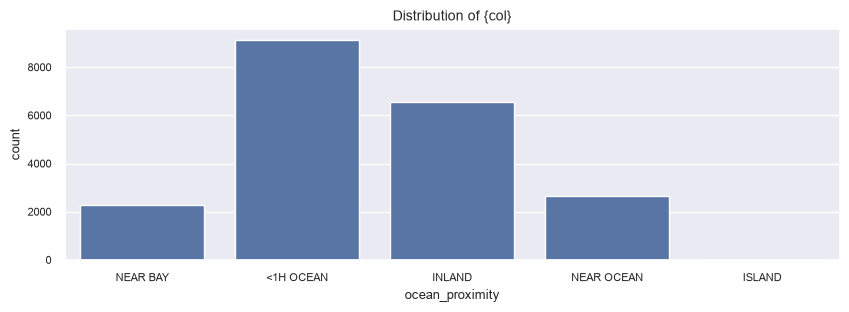

In [14]:
# countplot for categorical columns
for col in cat_cols:
    plt.figure(figsize=(10,3))
    sns.countplot(x=col, data=df)
    plt.title("Distribution of {col}")
    plt.show()

In [15]:
for col in cat_cols:
    print(df[col].value_counts())

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


We know that target column is important, so we are drawing an histogram plot for the `TARGET_COL` 

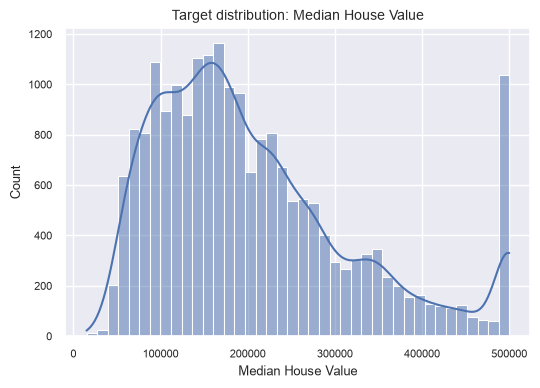

In [16]:
# target column distribution
plt.figure(figsize=(6,4))
sns.histplot(df[TARGET_COL], bins=40, kde=True)
plt.title("Target distribution: Median House Value")
plt.xlabel("Median House Value")
plt.show()

The main important things we understand from the **data** (in this case from the histogram), is that most of the data are situated in the range between 100.000 and 200.000. And this is pretty similar to a real-world scenario. And, at the end, let's break down about the last value, in this dataset we notice that so many houses has a price 500.000. There is a chance that in our dataset, the actual price of the houses is not 500.000, but like 1.000.000. So there is a chance that they have capped this larger amount to 500.000. So we can say that the model has a **limit** because it can't predict over this maximum price. The **model is as good as data**. So this maybe compromised the value of R squared error in our evaluation.

In [17]:
# higher cap
df[TARGET_COL].value_counts()

median_house_value
500001.000    965
137500.000    122
162500.000    117
112500.000    103
187500.000     93
             ... 
422900.000      1
349400.000      1
425800.000      1
200700.000      1
47000.000       1
Name: count, Length: 3842, dtype: int64

In this part of the code, we are going to iterate over all the numerical columns and draw histograms for this. We create one plot and we have these distribution plots as subplot.

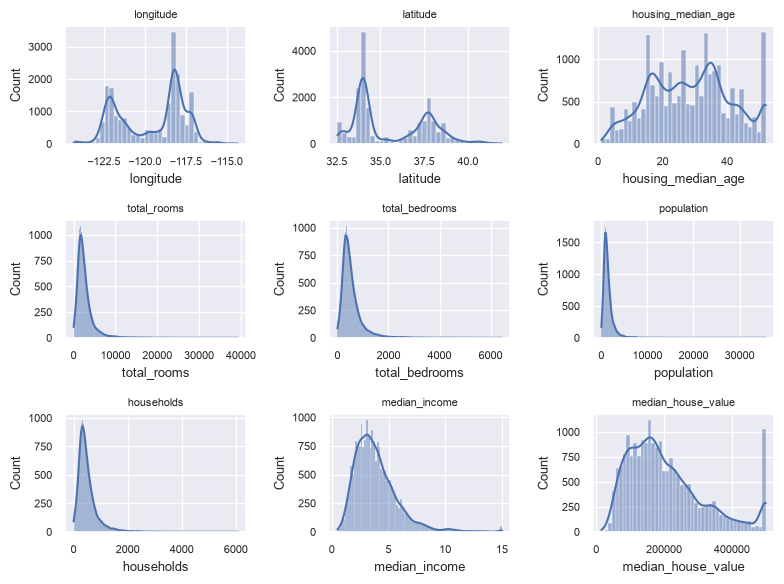

In [18]:
# histogram plot - distribution
fig, axes = plt.subplots(3, 3, figsize=(8,6))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, ax=axes[i])
    axes[i].set_title(col, fontsize=8)

plt.tight_layout()
plt.show()

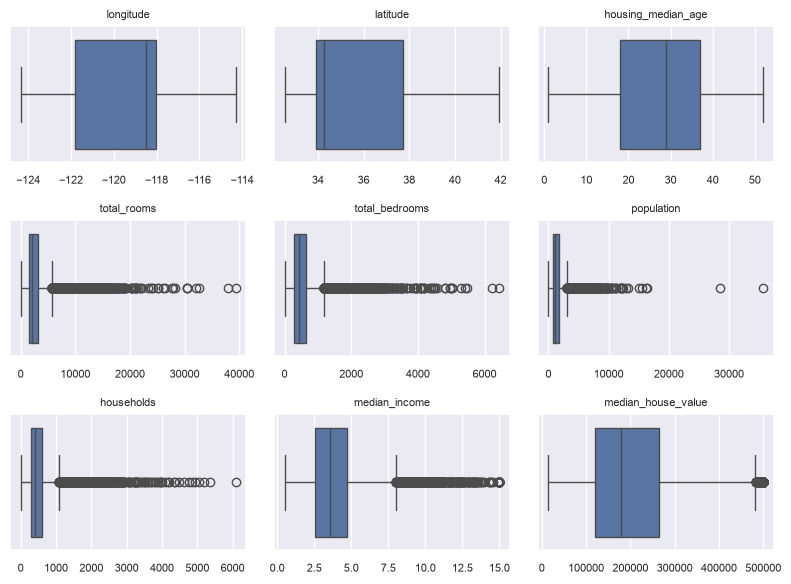

In [19]:
# outliers analysis - boxplot
fig, axes = plt.subplots(3, 3, figsize=(8,6))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(x=df[col], ax=axes[i])
    axes[i].set_title(col, fontsize=8)
    axes[i].set_xlabel("")

plt.tight_layout()
plt.show()

Now we draw a correlation heat map that gives us the relationship between different columns.

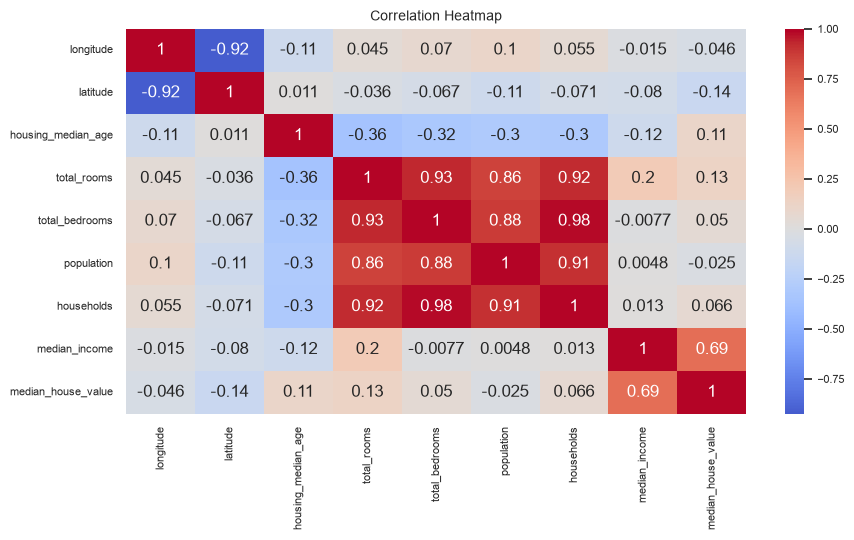

In [20]:
# identify presence of highly correlated columns & features relationships
plt.figure(figsize=(10, 5))
sns.heatmap(
    df[num_cols].corr(),
    annot=True,
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Heatmap")
plt.show()

We can also take the `median_house_value` and compare with the correlation

In [21]:
# correlation with target
corr_with_target = df[num_cols].corr()[TARGET_COL].sort_values(ascending=False)
print("\nCorrelation with target:")
print(corr_with_target)


Correlation with target:
median_house_value    1.000
median_income         0.688
total_rooms           0.134
housing_median_age    0.106
households            0.066
total_bedrooms        0.050
population           -0.025
longitude            -0.046
latitude             -0.144
Name: median_house_value, dtype: float64


##### Key Insights from EDA

- Dataset has numeric + one categorical feature (ocean_proximity)

- Only total_bedrooms has missing value

- Target (median_house_value) is right-skewed and capped

- Several features shows strong skew and outliers

- median_income is the strongest predictor

- High multicollinearity among room and population features

------------

##### Preprocessing & Evaluation Plan 

- Median imputation for missing values

- One-hot encoding for categorical feature

- Feature scaling for linear models 

- Use pipeline to avoid data leakage

- Baseline model -> CV model selection -> hyperparameter tuning

- Primary metric: RMSE, secondary: MAE and R squared 

- Final evaluation only on test set

4. Data Preprocessing

In [22]:
# separate features and target
X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL]

In [23]:
X.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
0,-122.230,37.880,41.000,880.000,129.000,322.000,126.000,8.325,NEAR BAY
1,-122.220,37.860,21.000,7099.000,1106.000,2401.000,1138.000,8.301,NEAR BAY
2,-122.240,37.850,52.000,1467.000,190.000,496.000,177.000,7.257,NEAR BAY
3,-122.250,37.850,52.000,1274.000,235.000,558.000,219.000,5.643,NEAR BAY
4,-122.250,37.850,52.000,1627.000,280.000,565.000,259.000,3.846,NEAR BAY


In [24]:
y.head()

0   452600.000
1   358500.000
2   352100.000
3   341300.000
4   342200.000
Name: median_house_value, dtype: float64

In [25]:
# train test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state=RANDOM_STATE
)

In [26]:
print("Train shape:", X_train.shape)

print("Test shape:", X_test.shape)

Train shape: (16512, 9)
Test shape: (4128, 9)


**Preprocessing Pipeline**

- The reason why we do this, it's because categorical features should go through a different set of pre-processing steps

- And on the other hand, the numerical features should go through a different set of things


In [27]:
numerical_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

#numerical features - preprocessing steps
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# categorical features - preprocessing steps
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# preprocessing pipeline
preprocess = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)  
    ]
)

Numerical features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
Categorical features: ['ocean_proximity']


The first step is `imputation`, so call this as `imputer`, then the second step is the `scaler`, here we can initiate a standard scaler. So this are the processing required for numerical transformer.

In the case of categorical columns, the missing values should be replaced with your mode value.

Numerical features should go through imputation and scaling and categorical columns shouldn't perform scaling.

Basically creating this pipeline, we are saying that numerical features should go through this imputation, where the missing values are going to be replaced with a median value. The simple imputer know this. When you give the strategy as median and saying that after imputation is done, scale this data using standard scaler only for numerical features.

And then we are creating a categorical transformer, in order to create a pipeline, where missing values in categorical should be replaced with `most_frequent` value, in other words our mode value 

5. Baseline model (No CV, No Tuning)

In [28]:
baseline_pipe = Pipeline(
    steps=[
        ("preprocess", preprocess),
        ("model", LinearRegression())
    ]
)

Instead of fit every time the data, we already have this pre-process pipeline using this `column transformer`. So we are creating another pipeline where the first step is `pre-processing` and the next step is the `model training`. When we call this `baseline pipe.fit` the data first goes through this pre-processing step (`numerical-transformation` and `categorical-transformation`)

In [29]:
# preprocess the data and train the baseline model
baseline_pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['longitude','latitude','housing_median_age',...,'households', 'median_income','ocean_proximity']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. 

So this is our **baseline pipeline** we have created

- The advantage, when we call this model for prediction for inference, all of this transformation would happen automatically. You don't have to manually impute the missing value. We simply call the `baseline_pipe` and that would take care of imputation standard scaling and getting the prediction from your model

##### Evaluation of baseline model

In [30]:
train_baseline_pred = baseline_pipe.predict(X_train)
test_baseline_pred = baseline_pipe.predict(X_test)

In [31]:
train_baseline_pred[:5]

array([188628.0772436 , 290379.8948687 , 250985.48476349, 146878.07878194,
       165789.41368924])

In [32]:
y_train[:5]

14196   103000.000
8267    382100.000
17445   172600.000
14265    93400.000
2271     96500.000
Name: median_house_value, dtype: float64

In [33]:
train_baseline_rmse = root_mean_squared_error(y_train, train_baseline_pred)
train_baseline_mae = mean_absolute_error(y_train, train_baseline_pred) 
train_baseline_r2 = r2_score(y_train, train_baseline_pred)

print("\n=== TRAIN BASELINE METRICS (LinearRegression) ===")
print(f"RMSE: {train_baseline_rmse:.3f}")
print(f"MAE: {train_baseline_mae:.3f}")
print(f"R2: {train_baseline_r2:.3f}")


=== TRAIN BASELINE METRICS (LinearRegression) ===
RMSE: 68433.937
MAE: 49594.842
R2: 0.650


In [34]:
test_baseline_rmse = root_mean_squared_error(y_test, test_baseline_pred)
test_baseline_mae = mean_absolute_error(y_test, test_baseline_pred)
test_baseline_r2 = r2_score(y_test, test_baseline_pred)

print("\n=== TEST BASELINE METRICS (LinearRegression) ===")
print(f"RMSE: {test_baseline_rmse:.3f}")
print(f"MAE: {test_baseline_mae:.3f}")
print(f"R2: {test_baseline_r2:.3f}")


=== TEST BASELINE METRICS (LinearRegression) ===
RMSE: 70059.193
MAE: 50670.489
R2: 0.625


6. Model Selection & Optimization

- We are going to create a dictionary, the key will be the name of the models that we want to try and the value will be the actual instance of these models.

In [35]:
# models to try
models = {
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(random_state=RANDOM_STATE),
    "Lasso": Lasso(random_state=RANDOM_STATE, max_iter=10000),
    "RandomForest": RandomForestRegressor(),
    "HistGB": HistGradientBoostingRegressor()
}

In [37]:
# cross validation fold
k = 5
cv = KFold(n_splits=k, shuffle=True, random_state=RANDOM_STATE)

In [40]:
scoring = {
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "r2": "r2"
}

Once we do this hyperparameter tuning, we are going to perform **cross-validation** on five different fold for each fold for each iteration, we are going to get the **negative root mean squared error**, **negative mean absolute error** and **r2 score** 

In [41]:
rows = []

for name, model in models.items():
    pipe = Pipeline(
        steps=[
            ("preprocess", preprocess),
            ("model", model)
        ]
    )
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    rows.append({
        "model": name,
        "cv_rmse": -scores["test_rmse"].mean(),
        "cv_mae": -scores["test_mae"].mean(),
        "cv_r2": -scores["test_r2"].mean()
    })

    # sort based on lowest rmse value
    cv_results = pd.DataFrame(rows).sort_values("cv_rmse")
    print("=== CV Model Comparison ===")
    print(cv_results)

=== CV Model Comparison ===
              model   cv_rmse    cv_mae  cv_r2
0  LinearRegression 68604.163 49667.159 -0.648
=== CV Model Comparison ===
              model   cv_rmse    cv_mae  cv_r2
1             Ridge 68595.617 49664.331 -0.648
0  LinearRegression 68604.163 49667.159 -0.648
=== CV Model Comparison ===
              model   cv_rmse    cv_mae  cv_r2
1             Ridge 68595.617 49664.331 -0.648
2             Lasso 68603.233 49667.263 -0.648
0  LinearRegression 68604.163 49667.159 -0.648
=== CV Model Comparison ===
              model   cv_rmse    cv_mae  cv_r2
3      RandomForest 49369.051 32295.608 -0.818
1             Ridge 68595.617 49664.331 -0.648
2             Lasso 68603.233 49667.263 -0.648
0  LinearRegression 68604.163 49667.159 -0.648
=== CV Model Comparison ===
              model   cv_rmse    cv_mae  cv_r2
4            HistGB 48147.292 32211.966 -0.827
3      RandomForest 49369.051 32295.608 -0.818
1             Ridge 68595.617 49664.331 -0.648
2             

Now we are going to perform cross validation where it happens five times. So we have five iterations and we get five different scores in five different model (**LinearRegression**, **Ridge**, **Lasso**, **RandomForest** and **HistGB**)

We have created `scores` and we call `cross_validate` that is a function we got from **sklearn.model_selection**.
The last argument of **cross_validate** is `n_jobs` that it makes sure that all the CPU cores runs for this multiple training of cross validation.

Here we can use thi **cross_validate** that is automatically going to fit the data and train the model and get the score. The reasons is sometime doing that steps manually give more control. But sometimes we can easily use this cross validate.

This training data will be split into **five folds** (like f1, f2, f3, f4, f5). When the model train for the first time, in the first iteration, this **f5** will be our `test data` and the remaining four is the `training data`. Second iteration the **f4** will be our test data and the remaining the training data, and this process goes on and on. So basically we are training one model five times with these five different iteration

When the **for loop** runs for the first time, the `name` take the value of `LinearRegression`, and the `model` variable take the value of `LinearRegression` instance. Then we have creating a new **pipe**, where the first **process** the same **pre-processing** step. But the pre-processing is not going to change as we have defined it earlier. Model is a changing parameter. So at each iteration of the **for loop** this model name will change.

So the first time for loop runs this pipe as linear regression model in it and cross-validation happens. Next time it has `ridge regression`, and so on.